# Hackathon 1, statistics.

This project illustrates the statistics part of the course LEPL1109. In the first part of the project, you will study the mortality observed in Belgium. In the second part of the project, you try to predict the electricity consumption in Belgium using climate variables.

## Report content

•	Grades are granted to the members whose names are in the Jupyter notebook. If your name doesn’t appear on the top of the notebook, you’ll get a 0, even though you are in a group on Moodle.

•	The jupyter notebook must be compiled with printed results and next submitted via moodle. The absence of compiled results (or non-printed values) leads to a lower grade.

•	Do not comment your results directly into cells of code. Use instead a Markdown cell. 

•	"Dry" code or results not followed by a minimum of analysis / comments will be penalized.


## Report submission

•	Deadline, see moodle website. Submission after the deadline will not be accepted.

•	To submit your report, go to the section “Hackathon” on Moodle and the subsection “Remise Hackathon 1”. You can upload your work there. Once you are sure that it is your final version, click the button “Envoyer le devoir”. It is important that you don’t forget to click on this button ! 

•	Reports that have not been uploaded through Moodle will not be corrected.


## Names and Noma of participants:

Part. 1: Aurélie Wanson 79632400

Part. 2: Aurore Chaltin 17952301

Part. 3: Jérémy Cruysberghs 39092400

Part. 4: Anh-Tien Le 54992400

Part. 5: Titouan Willermain 65422300

Part. 6: Albéric Carrette 40962400

# Mortality and climate

In this section, we analyze the relationship between mortality, age groups, and seasons in Belgium using publicly available data from Statbel (see https://statbel.fgov.be/en/about-statbel/what-we-do/visualisations/mortality). The dataset contains the number of deaths recorded over time, disaggregated by age group and observed across different seasons. The objective is to study temporal patterns in mortality and assess the role of seasonal effects. 

## 1. Basic statistics

**1.1)** Load the dataset mortality_climate.csv. Convert the variables *season* and *CD_AGEGROUP* into a categorical variable. 

In [33]:
import pandas as pd

df = pd.read_csv('mortality_climate.csv')

df['season'] = df['season'].astype('category')
df['CD_AGEGROUP'] = df['CD_AGEGROUP'].astype('category')

print(df.dtypes)


date                 str
season          category
CD_AGEGROUP     category
MS_NUM_DEATH       int64
dtype: object


**1.2)** Plot the evolution of the number of deaths (*MS_NUM_DEATH*) with respect to age group. What do you observe?

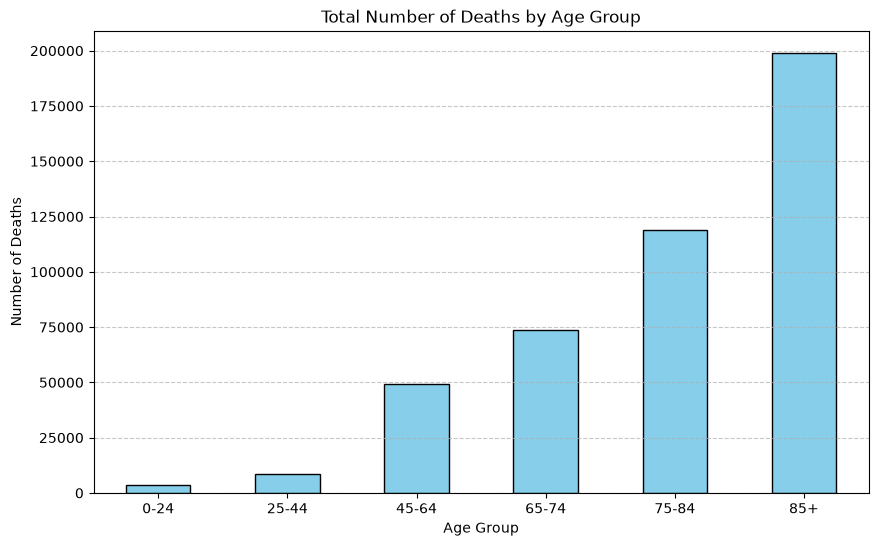

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('mortality_climate.csv')
df['CD_AGEGROUP'] = df['CD_AGEGROUP'].astype('category')

deaths_by_age = df.groupby('CD_AGEGROUP')['MS_NUM_DEATH'].sum()

plt.figure(figsize=(10, 6))
deaths_by_age.plot(kind='bar', color='skyblue', edgecolor='black')

plt.title('Total Number of Deaths by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Deaths')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show() 


Comments:

**1.3)** Do a scatter plot of the number of deaths (*MS_NUM_DEATH*) by age group.

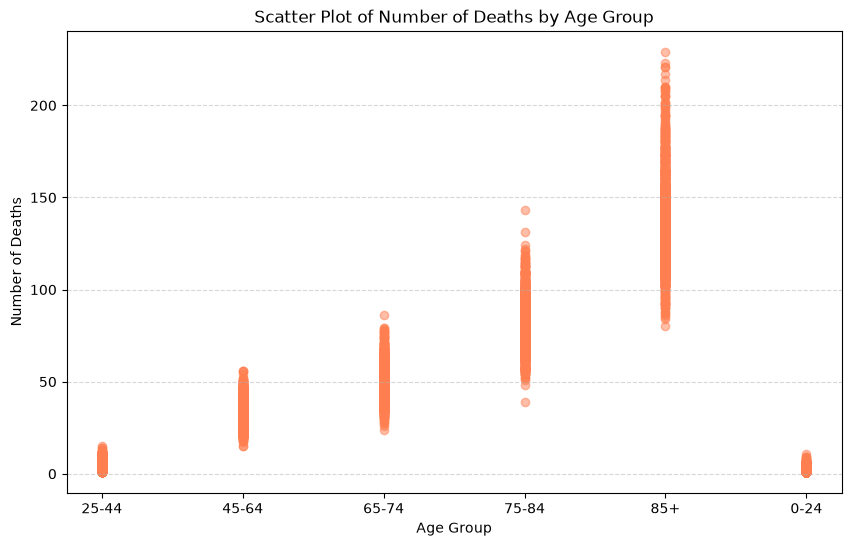

<Figure size 1000x600 with 0 Axes>

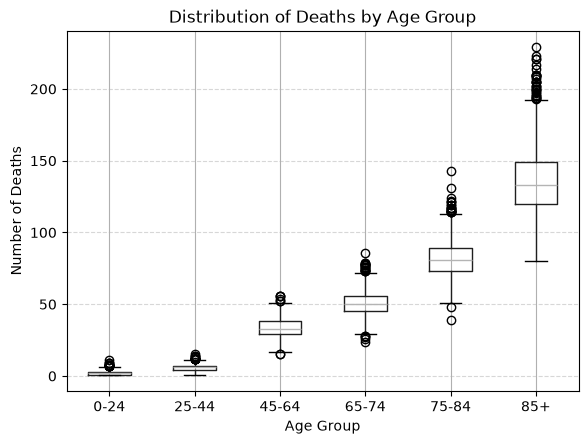

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df['CD_AGEGROUP'], df['MS_NUM_DEATH'], alpha=0.5, color='coral')

plt.title('Scatter Plot of Number of Deaths by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Deaths')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

df = pd.read_csv('mortality_climate.csv')

age_order = ['0-24', '25-44', '45-64', '65-74', '75-84', '85+']
df['CD_AGEGROUP'] = pd.Categorical(df['CD_AGEGROUP'], categories=age_order, ordered=True)

plt.figure(figsize=(10, 6))
df.boxplot(column='MS_NUM_DEATH', by='CD_AGEGROUP', grid=True)

plt.title('Distribution of Deaths by Age Group')
plt.suptitle('') 
plt.xlabel('Age Group')
plt.ylabel('Number of Deaths')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()


Comments: 

## 2. Fit of distributions

**2.1)** For the 45–64 age group and the winter season only, fit both a Poisson and a Negative Binomial distribution to the variable 'MS_NUM_DEATH' using a maximum likelihood approach. Plot histograms overlaid with the fitted probability mass functions. Compare the log-likelihoods and select the most appropriate distribution.

In [36]:
# Code here


Comments: 

# 3. Regression

We now aim to assess whether seasonality has an impact on the number of deaths. We consider the following linear model:
$$\log(Y_i) = \beta_0 + \beta_1 X^S_{i1} + \cdots + \beta_3 X^S_{i3} + \beta_4 X^{age}_{i1} + \cdots + \beta_8 X^{age}_{i5}  + \varepsilon_i.$$

where $Y_i$ denotes the number of deaths, $X^S_{ij}$ are dummy variables representing the different seasons, $X^{age}_{ij}$ are dummy variables representing the different age groups, and $\varepsilon_i \sim N(0, \sigma^2)$. 

**3.1)** Why is it more appropriate to use a linear regression on $\log(Y)$ rather than directly on $Y$?

Comments:

**3.2)** Perform a linear regression of the number of deaths on the seasonal and group age covariates. Use the `OLS` function from the *statsmodels* package. Make sure to convert the variable *season* and *CD_AGEGROUP* into dummy variables before fitting the model.

Does seasonality have a significant impact on mortality? Is the mortality similar for each age group? 

In [37]:
# Code here


Comments: 

## 4. Hypothesis test 

We now investigate whether mortality decreases over time by comparing mortality in summer in 2022 and 2025. To this end, we aim to perform the following hypothesis test:

$$
H_0 : \mu_{2022} = \mu_{2025},
$$

$$
H_1 : \mu_{2022} \neq \mu_{2025}.
$$

**4.1)** Create two subsets of the original dataset corresponding to the years 2022 and 2025, respectively.

In [38]:
df['year'] = df['date'].str[:4]

df_2022 = df[df['year'] == '2022']
df_2025 = df[df['year'] == '2025']

print("Années présentes :", df['year'].unique())
print("Nombre de lignes en 2022 :", len(df_2022))
print("Nombre de lignes en 2025 :", len(df_2025))


Années présentes : <StringArray>
['2022', '2023', '2024', '2025']
Length: 4, dtype: str
Nombre de lignes en 2022 : 2166
Nombre de lignes en 2025 : 2151


**4.2)** For the 85+ age group, perform a Student’s t-test to compare mortality between 2022 and 2025 **in summer**. Check whether the assumptions required to apply this test are satisfied.

n1 = 94  moyenne = 129.7872340425532  écart-type = 17.32663580722605
n2 = 94  moyenne = 123.80851063829788  écart-type = 22.47544734241837


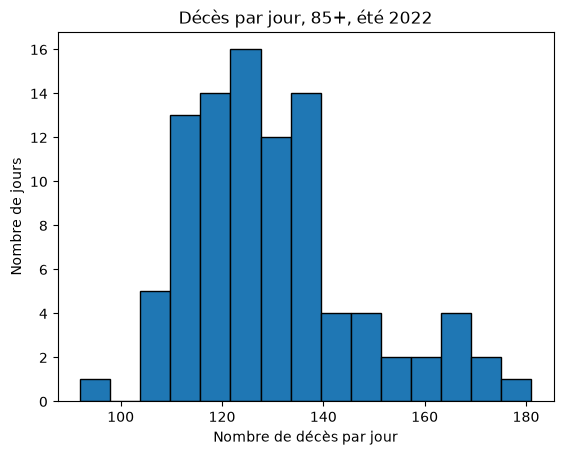

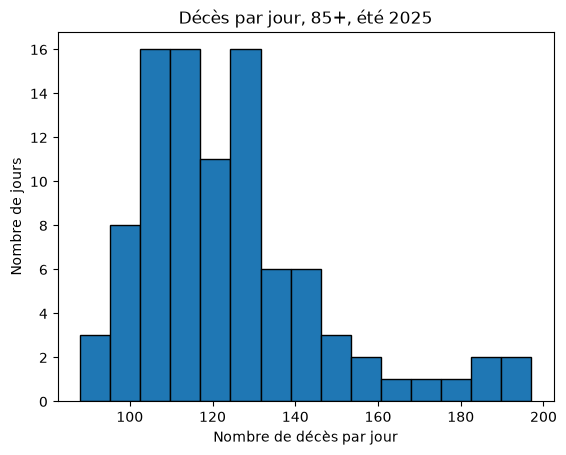

Rapport des variances : 0.5943083127112779
Bartlett : statistique = 6.192374399334855  p-value = 0.012830192936213116
Shapiro 2022 : ShapiroResult(statistic=np.float64(0.9371927100997304), pvalue=np.float64(0.00021183110593751768))
Shapiro 2025 : ShapiroResult(statistic=np.float64(0.8914809974355249), pvalue=np.float64(1.101253271523858e-06))
Statistique T = 2.0425744211253747
Zone de non-rejet : [ -1.972800113995442 , 1.9728001139954414 ]
p-value = 0.04250576221245899
scipy : 2.0425744211253747 0.04250576221245899


In [39]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as sc


X1 = df_2022[(df_2022['CD_AGEGROUP'] == '85+') & (df_2022['season'] == 'summer')]['MS_NUM_DEATH'].values
X2 = df_2025[(df_2025['CD_AGEGROUP'] == '85+') & (df_2025['season'] == 'summer')]['MS_NUM_DEATH'].values

n1 = len(X1)
n2 = len(X2)
Xb1 = np.mean(X1)
Xb2 = np.mean(X2)
S1 = np.std(X1, ddof=1)
S2 = np.std(X2, ddof=1)

print("n1 =", n1, " moyenne =", Xb1, " écart-type =", S1)
print("n2 =", n2, " moyenne =", Xb2, " écart-type =", S2)

plt.hist(X1, bins=15, edgecolor='black')
plt.title("Décès par jour, 85+, été 2022")
plt.xlabel("Nombre de décès par jour")
plt.ylabel("Nombre de jours")
plt.show()

plt.hist(X2, bins=15, edgecolor='black')
plt.title("Décès par jour, 85+, été 2025")
plt.xlabel("Nombre de décès par jour")
plt.ylabel("Nombre de jours")
plt.show()


print("Rapport des variances :", S1**2 / S2**2)
Tb, pb = sc.bartlett(X1.astype(float), X2.astype(float))
print("Bartlett : statistique =", Tb, " p-value =", pb)

print("Shapiro 2022 :", sc.shapiro(X1))
print("Shapiro 2025 :", sc.shapiro(X2))

Spool = np.sqrt(((n1-1)*S1**2 + (n2-1)*S2**2) / (n1 + n2 - 2))
Tx = (Xb1 - Xb2) / (Spool * np.sqrt(1/n1 + 1/n2))

alpha = 0.05
t_l = sc.t.ppf(q=alpha/2, df=n1+n2-2)
t_u = sc.t.ppf(q=1-alpha/2, df=n1+n2-2)
pval = 2 * sc.t.cdf(-np.abs(Tx), df=n1+n2-2)

print("Statistique T =", Tx)
print("Zone de non-rejet : [", t_l, ",", t_u, "]")
print("p-value =", pval)

T_sc, p_sc = sc.ttest_ind(X1, X2, equal_var=True)
print("scipy :", T_sc, p_sc)


Comments:

**4.3)** Explain what the Wilcoxon test is. Why could it be relevant in our setting?

Comments: 

**4.4)** For the 85+ age group, perform a Wilcoxon test to compare mortality between 2022 and 2025 **in summer**. What do you conclude?

In [40]:
U, p_mw = sc.mannwhitneyu(X1, X2, alternative='two-sided')
print("Statistique U =", U)
print("p-value =", p_mw)

Statistique U = 5555.0
p-value = 0.002309491592832224


Comments:

**4.5)** Perform the Wilcoxon test but now for the 25–44 age group and the **summer**. What do you conclude in this case?

In [41]:
Y1 = df_2022[(df_2022['CD_AGEGROUP'] == '25-44') & (df_2022['season'] == 'summer')]['MS_NUM_DEATH'].values
Y2 = df_2025[(df_2025['CD_AGEGROUP'] == '25-44') & (df_2025['season'] == 'summer')]['MS_NUM_DEATH'].values

U2, p_mw2 = sc.mannwhitneyu(Y1, Y2, alternative='two-sided')
print("Statistique U =", U2)
print("p-value =", p_mw2)
print("Moyenne 2022 =", np.mean(Y1), " Moyenne 2025 =", np.mean(Y2))


Statistique U = 4651.5
p-value = 0.5285373504458225
Moyenne 2022 = 6.148936170212766  Moyenne 2025 = 5.946808510638298


Comments: 

# Electricity Consumption and Climate

In this section, we aim to predict electricity consumption using past consumption values and climatic variables. We rely on data provided by ELIA (see https://opendata.elia.be/explore/dataset/ods003/information/?sort=datetime), which records total electricity consumption in Belgium at a 15-minute frequency, and meteorological data from the Royal Meteorological Institute (IRM) (see https://www.meteo.be/fr/services/donnees), which provides daily average temperature observations over Belgium.

The goal is to build a predictive model for electricity demand based on its recent history and weather conditions. From a practical perspective, such forecasting is highly relevant for energy providers and grid operators, as accurately anticipating electricity demand one week ahead helps optimize production planning, ensure grid stability, and reduce operational costs.

## 5. Forecasting 

The goal is to predict electricity consumption at time $t$ using its past values and climate features. Let $Y_t$ denote electricity consumption at time $t$. We consider the following regression model:

$$Y_t = \beta_0 + \beta_1 Y_{t-7Days} + \beta_2 \bar{T}_{t-7Days} + \beta_3 \bar{T}_{t-7Days}^2 + \varepsilon_t,$$

where $Y_{t-7Days}$ denotes electricity consumption observed 7 days earlier, $\bar{T}_{t-7Days}$ is the average temperature observed 7 days earlier$^1$, and $\varepsilon_t \sim \mathcal{N}(0,\sigma^2)$ is an error term.

$^1$ The average temperature is measured at a daily frequency; therefore, $\bar{T}_{t-7Days}$ is constant for all time points $t$ within the same day.

**5.1)** Load the dataset *electricity_climate.csv* and construct the dataset required to perform the regression.

**Warning:** the data are observed at 15-minute intervals.

To build the regression dataset, each row must contain:
- electricity consumption at time $t$: $Y_t$,
- electricity consumption at time $t - 7$ days: $Y_{t-7Days}$,
- temperature at time $t - 7$ days: $\bar{T}_{t-7Days}$,
- the squared temperature at time $t - 7$ days: $\bar{T}_{t-7Days}^2$.

In [42]:
# Code here 


**5.2)** Split the dataset into a training set (first 75%) and a test set (last 25%).  Use the `OLS` function from the *statsmodels* package to fit linear regression model using only $Y_{t-7Days}$ as explanatory variable.

Analyze the regression output, discuss the statistical significance and performance of the model.

In [43]:
# Code here 


Comments:

**5.3)** Repeat the regression by including the climate variables in the model.

Are the climate variables statistically significant in explaining electricity consumption 7 days ahead?

In [44]:
# Code here


Comments: 

**5.4)** Compute the MAE and RMSE on the test set for both models: with and without climate variables.

Does the inclusion of climate variables improve the predictive performance of the model?

In [45]:
# Code here 


Comments: 

**5.5)** For the model including climate variables, plot the predicted electricity consumption versus the true consumption on the test set. Then, produce a second plot focusing only on the first 7 days of the test set.

In [46]:
# Code here 


Comments: